### P2.3 — Deep Learning Foundations | Python to Gen AI Course
### P2.3.7 — CNN — Convolutional Neural Network


---
## 🔁 Quick Recap — Where We Are

In the previous notebook we built an ANN for tabular data.  
ANN works beautifully when your features are structured rows and columns.

But what happens when your data is an **image?**

---
## 👁️ Why ANN Fails on Images

Think about recognizing a face:

```
ANN approach:
┌─────────────────┐
│ Image as a list │
│ of 784 numbers  │    ANN says: "I see numbers.
│ in a row        │    I don't know if they're related to each other."
│ [0, 0, 255, ..] │
└─────────────────┘
           ↓
    Fails to realize that nearby pixels form eyes, noses, etc.


CNN approach:
┌──────────────────┐
│ Image AS A GRID  │    CNN says: "I see a 2D picture.
│ (preserves 2D    │    I can look for patterns like edges,
│  structure)      │    curves, and shapes."
│  ┌────┐          │
│  │ 👁 │          │
│  └────┘          │
└──────────────────┘
           ↓
    Recognizes features and their locations easily.
```

**In simple terms:**
- **ANN:** Treats image as just a pile of numbers — loses the fact that they're arranged in a grid
- **CNN:** Treats image as a picture — respects the grid layout


<img src="images/ann_vs_cnn.png" width="800"/>

---
## 🔍 The Key Idea — Convolution (Filters)

Instead of connecting every pixel to every neuron —  
CNN uses small **filters** (also called kernels) that slide across the image.

```
A filter is a small grid — e.g. 3×3

  [ 1  0 -1 ]
  [ 1  0 -1 ]  ← This filter detects vertical edges
  [ 1  0 -1 ]
```

The filter slides across the image, one step at a time.  
At each position, it computes a dot product with the pixels underneath it.  
The result is a new grid called a **Feature Map** — showing where that pattern appears.

```
Image           Filter slides          Feature Map
(28×28)         across image     →     (detects edges)

  ┌─────────┐                          ┌─────────┐
  │  pixels │   [3×3 filter]           │  edges  │
  │  ██ ██  │ ──────────────────────▶  │ detected│
  │  ██████ │                          │         │
  └─────────┘                          └─────────┘
```

**One CNN layer uses many filters in parallel:**
```
Filter 1  →  detects vertical edges
Filter 2  →  detects horizontal edges
Filter 3  →  detects diagonal edges
Filter 4  →  detects curves
...
32 filters → 32 feature maps — one per pattern
```

The CNN **learns** what patterns each filter should detect —  
it is not hand-coded. The weights in each filter are learned during training.

<img src="images/convolution.png" width="800"/>

---
<img src="images/f_extraction_1.png" width="800"/>
---
<img src="images/f_extraction_2.png" width="800"/>
---
<img src="images/f_extraction_3.png" width="800"/>


---
## 🌊 Pooling — Shrinking While Keeping What Matters

After convolution, we have feature maps — but they can still be large.  
**Pooling** reduces the size while keeping the most important information.

The most common type is **Max Pooling:**

```
Take a 2×2 window, slide across the feature map
At each position — keep only the maximum value

Before Max Pooling (4×4):        After Max Pooling (2×2):
  1   3   2   4                     3   4
  5   6   1   2       ──────▶        6   4
  3   2   4   1
  1   5   2   3
```

Why does this work?  
If an edge is detected somewhere in a 2×2 region — the exact pixel does not matter.  
The max value captures **whether** the feature is present, not exactly where.

**Benefits of Pooling:**
```
✅  Reduces the size of feature maps — fewer parameters downstream
✅  Reduces computation
✅  Makes the detection slightly position-invariant
   (a slightly shifted eye is still recognised as an eye)
```

<img src="images/max_pooling.png" width="700"/>

---
## 🧹 Flatten — Bridging Feature Extraction and Classification

After Conv + Pool layers, we have a stack of 2D feature maps.
But Dense layers (the classification part) only accept a **1D list of numbers**.

**Flatten just unrolls the 2D grids into one long vector — no math, no learning, just reshaping.**

```
After two Conv+Pool stages (example — MNIST):

  Feature maps shape:  (7, 7, 64)    ←  7×7 spatial grid, 64 filters
                           ↓ flatten
  Vector shape:        (3136,)        ←  7 × 7 × 64 = 3136 numbers in a row
```

Think of it like **unfolding a stack of grids into one long strip** so the Dense layers can read it.

```
  [ grid ]                       
  [ grid ]   → flatten →  [1, 2, 3, 4, 5, 6 ... 3136 numbers]
  [ grid ]                       
```

> 💡 After flatten, the CNN transitions into ANN-style dense layers — the same fully connected logic you already know from P2.3.6.
<img src="images/cnn_class.png" width="700"/>
---
<img src="images/cnn_intro.png" width="700"/>

---
## 🎯 CNN Pipeline — Classification

Classification answers: **"What is in this image?"**
Output = one label (or probabilities across N classes).

```
Input Image
    ↓
Conv(32 filters) + ReLU   ← learns low-level patterns (edges, gradients)
    ↓
MaxPool                   ← shrink, keep strongest signals
    ↓
Conv(64 filters) + ReLU   ← learns higher-level patterns (shapes, textures)
    ↓
MaxPool
    ↓
Flatten                   ← (7,7,64) → 3136 numbers
    ↓
Dense(128) + ReLU         ← combine features, learn class separations
    ↓
Dense(N) + Softmax        ← output: probability for each of N classes
```

**Output example (MNIST — 10 classes):**
```
Input: image of digit "7"
Output: [0.01, 0.00, 0.02, 0.00, 0.00, 0.01, 0.00, 0.95, 0.00, 0.01]
            0     1     2     3     4     5     6     7     8     9
Prediction: class 7  (highest probability)
```

<img src="images/cnn_architecture.png" width="700"/>

---
## 📦 CNN Pipeline — Object Detection

---

### 🔄 Same Backbone. Completely Different Head.

Classification and Detection **share the same feature extraction steps** — Conv layers and Pooling.
But after that, the head is a completely different design:

```
Classification   →  Flatten → Dense → ONE label per image
Detection        →  Region search → Detection head → MANY boxes + labels per image
```

> 💡 Think of the backbone as a shared eye — both tasks use it to see features.
> But classification just names what it sees, while detection also points to where each thing is.

---

### 📋 Key Terms Before the Pipeline

**Bounding Box**
> A rectangle drawn around a detected object, described by 4 numbers: `[x, y, width, height]`
> `x, y` = top-left corner of the box. Width and height define its size.

**Anchor Boxes / Region Proposals**
> The model can't look at every possible rectangle in the image — there are millions.
> Instead, it uses **predefined candidate regions** called anchor boxes:
> - YOLO divides the image into a grid (e.g. 13×13 cells)
> - Each cell predicts whether an object is there, and adjusts a set of preset box shapes
> - These candidate regions are then scored and filtered

**Confidence Score**
> A number between 0–1 saying how sure the model is that an object is in a given box.
> Low confidence boxes get discarded.

**Non-Max Suppression (NMS)**
> The model often predicts multiple overlapping boxes for the same object.
> NMS keeps only the box with the highest confidence and removes the rest.
> Result: one clean box per object, no duplicates.

---

### 🗺️ The Detection Pipeline

Detection answers: **"What is in this image, and WHERE is it?"**

```
Input Image
    ↓
Conv + ReLU               ← learn low-level patterns (edges, shapes)
    ↓
Pooling                   ← shrink, keep strongest signals
    ↓
Conv + ReLU               ← learn higher-level patterns (textures, objects)
    ↓
Pooling
    ↓
Anchor Boxes / Grid       ← divide image into regions, check each for objects
    ↓
Detection Head            ← for each region, predict:
    ↓                          • class label   (what is it?)
    ↓                          • confidence    (how sure?)
    ↓                          • bounding box  [x, y, width, height]
Non-Max Suppression (NMS) ← remove duplicate overlapping boxes, keep best
    ↓
Final Output              ← list of objects with labels, scores, and boxes
```

<img src="images/detection_pipeline.png" width="850"/>

**Output example (YOLO on a street photo):**
```
Object 1: "person"  confidence: 0.97  box: [120, 45, 60, 180]
Object 2: "car"     confidence: 0.91  box: [300, 90, 200, 140]
Object 3: "dog"     confidence: 0.83  box: [50, 210, 80, 90]
```

<img src="images/classification_vs_detection.png" width="750"/>

> 👉 Example 3 uses YOLO — you will see this exact pipeline running on a real image.

---

## 🗺️ What We Cover in This Notebook

| # | Example | Task | Dataset | Approach |
|---|---|---|---|---|
| 1 | Handwritten Digits | Classification | MNIST (Large) | CNN from Scratch |
| 2 | Cats vs Dogs | Classification | Kaggle (Small) | Pretrained + Fine Tuning |
| 3 | Human Detection | Object Detection | COCO (80 classes) | Pretrained YOLO |

---

## 💻 Should I run this on Google Colab or Local?

```
Google Colab  ✅ Recommended for Examples 1 and 2
  → Free GPU available
  → No installation needed
  → Example 1 (MNIST): 20-25 mins on CPU vs 1-2 mins on GPU
  → Example 2 (Cats vs Dogs): similar speedup

Local (VSCode / Jupyter)  ✅ Fine for Example 3
  → YOLO only does inference — no heavy training
  → CPU handles it in 1-3 seconds per image
```

**How to enable GPU in Colab:**
```
Runtime → Change runtime type → Hardware accelerator → GPU → Save
```

---
# 📦 EXAMPLE 1 — CNN from Scratch
## Task: Image Classification | Dataset: MNIST | Size: Large (70,000 images)

---

## What is MNIST?

```
70,000 handwritten digit images
  → 60,000 for training
  → 10,000 for testing

Each image:
  → 28×28 pixels        ← very small! (about the size of a thumbnail)
  → Grayscale           ← black and white, 1 channel
  → 1 pixel = 0 to 255  ← 0 is black, 255 is white

10 classes: digits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9
```

## Why CNN from Scratch here?

```
70,000 images is LARGE enough to train from random weights
No pretrained model needed — the CNN learns everything by itself
```

## What does "Classification" mean here?

```
Input  → 28×28 image of a handwritten digit
Output → ONE label from 10 choices (0 to 9)

The model does NOT generate images
The model does NOT describe the image
It simply says: "This is a 7"
```

In [ ]:
# ─── INSTALL (run once) ───────────────────────────────────────────
! pip install tensorflow numpy matplotlib scikit-learn
print("Libraries ready ✅")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# ── LOAD DATA ─────────────────────────────────────────────────────
# MNIST is built into Keras — no manual download needed
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print(f"Train images : {X_train.shape}  → {X_train.shape[0]} images of {X_train.shape[1]}×{X_train.shape[2]} pixels")
print(f"Test  images : {X_test.shape}")
print(f"Labels       : {np.unique(y_train)}  (digits 0 to 9)")
print(f"Pixel range  : {X_train.min()} to {X_train.max()}  (raw, before normalization)")

In [ ]:
# ── PHASE 1: PREPARE ─────────────────────────────────────────────

# CNN expects shape: (samples, height, width, channels)
# Grayscale = 1 channel  |  Color (RGB) = 3 channels
X_train = X_train.reshape(-1, 28, 28, 1)
X_test  = X_test.reshape(-1, 28, 28, 1)

# Normalize pixels from 0-255 → 0-1
# Why? Keeps all values on same scale — model trains faster and better
X_train = X_train / 255.0
X_test  = X_test  / 255.0

print("Data prepared:")
print(f"  Shape after reshape : {X_train.shape}")
print(f"  Pixel range now     : {X_train.min()} to {X_train.max()}  (normalized)")

In [ ]:
# ── PHASE 2: BUILD CNN ────────────────────────────────────────────

# Stage 1 — Feature Extraction (CNN layers)
# Stage 2 — Classification (Dense layers — same as ANN)

model = keras.Sequential([

    # Stage 1: Feature Extraction
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    # 32 filters, each 3×3 → slides across image → detects 32 patterns (edges, curves)
    layers.MaxPooling2D((2,2)),
    # Shrinks feature maps by half → reduces computation

    layers.Conv2D(64, (3,3), activation='relu'),
    # 64 filters → detects higher patterns (shapes, strokes) from previous layer's output
    layers.MaxPooling2D((2,2)),

    # Stage 2: Classification
    layers.Flatten(),
    # Converts 2D feature maps → 1D list of numbers

    layers.Dense(128, activation='relu'),
    # Fully connected — combines all detected features

    layers.Dense(10, activation='softmax')
    # 10 output neurons — one per digit (0-9)
    # Softmax → probabilities that sum to 1.0
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # multi-class with integer labels
    metrics=['accuracy']
)

model.summary()

In [ ]:
# ── PHASE 2: TRAIN ────────────────────────────────────────────────
# On CPU  → ~20-25 minutes
# On Colab GPU → ~1-2 minutes ✅

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=5,
    batch_size=64,
    verbose=1
)

In [ ]:
# ── PHASE 3: EVALUATE ─────────────────────────────────────────────
train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
test_loss,  test_acc  = model.evaluate(X_test,  y_test,  verbose=0)

train_acc = round(train_acc * 100, 2)
test_acc  = round(test_acc  * 100, 2)

print("=== EVALUATE ===")
print(f"  Train Accuracy : {train_acc}%")
print(f"  Test  Accuracy : {test_acc}%")

gap = train_acc - test_acc
if gap < 2:
    print("  ✅ Good Fit — train and test scores are close")
elif gap > 10:
    print("  ⚠️  Overfitting — model memorised training data")
else:
    print("  ✅ Acceptable — small gap, generalises well")

In [ ]:
# ── PHASE 4: INFERENCE on test set images ─────────────────────────
# We pass images the model has NEVER seen during training
# Output is a LABEL — not an image

sample_images = X_test[:5]
sample_labels = y_test[:5]

predictions      = model.predict(sample_images, verbose=0)
predicted_digits = np.argmax(predictions, axis=1)
# argmax picks the class with highest probability from 10 outputs

# Show images with predictions
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    ax = axes[i]
    ax.imshow(sample_images[i].squeeze(), cmap='gray')
    # .squeeze() removes channel dimension: (28,28,1) → (28,28)
    confidence = round(predictions[i][predicted_digits[i]] * 100, 1)
    status = "✅" if predicted_digits[i] == sample_labels[i] else "❌"
    ax.set_title(f"Actual: {sample_labels[i]}\nPred: {predicted_digits[i]} ({confidence}%) {status}")
    ax.axis('off')
plt.suptitle("MNIST Inference — Test Set Images", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
# 🐱🐶 EXAMPLE 2 — Pretrained CNN + Fine Tuning
## Task: Image Classification | Dataset: Cats vs Dogs | Size: Small (~25,000 images)

---

## Why NOT from Scratch here?

```
MNIST had 70,000 clean, simple digit images  → scratch works fine
Cats vs Dogs has 25,000 complex photos       → not enough to learn from scratch

Real world photos have:
  → complex textures (fur, skin)
  → varying backgrounds
  → different lighting
  → many sizes and angles

Learning all this from 25,000 images = poor accuracy ❌
```

## Solution: Transfer Learning + Fine Tuning

```
VGG16 — a CNN pretrained on ImageNet
  → ImageNet = 1.2 million images, 1000 classes
  → VGG16 already knows: edges, curves, textures, shapes

We BORROW this knowledge and ADAPT it for our task
```

## What is Fine Tuning?

```
VGG16 was trained on 1000 classes
Our task = only 2 classes (Cat or Dog)

So we:
  STEP 1 → Load VGG16 (pretrained weights)
  STEP 2 → FREEZE early layers  ← don't retrain, reuse as-is
  STEP 3 → REMOVE final layer   ← was 1000 classes
  STEP 4 → ADD new final layer  ← our 2 classes
  STEP 5 → TRAIN only new layer ← on our Cats vs Dogs data

Why freeze early layers?
  → They already learned edges, textures, shapes
  → These patterns are UNIVERSAL — useful for any image task
  → Retraining them wastes time and needs more data
```

<img src="images/transfer_learning.png" width="750"/>

## Classification here means:

```
Input  → Color photo of a cat or dog (224×224 pixels, RGB)
Output → ONE label: "Cat" or "Dog"

Still classification — just 2 classes instead of 10
```

In [ ]:
# ─── INSTALL (run once) ───────────────────────────────────────────
! pip install tensorflow tensorflow-datasets numpy matplotlib --quiet
print("Libraries ready ✅")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
import tensorflow_datasets as tfds

# ── LOAD Cats vs Dogs dataset ──────────────────────────────────────
# Available directly in TensorFlow Datasets — no manual download
(train_ds, val_ds), info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,   # returns (image, label) pairs
    with_info=True
)

print("Dataset loaded ✅")
print(f"Total training samples : {info.splits['train'].num_examples}")
print(f"Classes                : 0 = Cat, 1 = Dog")

In [ ]:
# ── PHASE 1: PREPARE ─────────────────────────────────────────────
# VGG16 expects 224×224 color images (not 28×28 like MNIST)
# Images come in different sizes — we resize them all

def preprocess(image, label):
    image = tf.image.resize(image, (224, 224))  # resize to 224×224
    image = image / 255.0                        # normalize 0-1
    return image, label

train_ds = train_ds.map(preprocess).batch(32)
val_ds   = val_ds.map(preprocess).batch(32)

print("Data prepared:")
print(f"  Image size : 224×224 pixels (VGG16 requirement)")
print(f"  Channels   : 3 (RGB color — unlike MNIST's 1 grayscale channel)")
print(f"  Batch size : 32")

In [ ]:
# ── PHASE 2: LOAD PRETRAINED VGG16 ───────────────────────────────

base_model = VGG16(
    weights='imagenet',      # use weights trained on 1.2M ImageNet images
    include_top=False,       # remove the final 1000-class layer
    input_shape=(224, 224, 3)
)

# FREEZE all pretrained layers
# We don't want to change what VGG16 already learned
base_model.trainable = False

print("VGG16 loaded and frozen ✅")
print(f"VGG16 layers frozen  : {len(base_model.layers)}")
print("These layers already know: edges, curves, textures, shapes")

In [ ]:
# ── PHASE 2: ADD OUR CLASSIFICATION HEAD ─────────────────────────

model = keras.Sequential([
    base_model,                           # frozen VGG16 — feature extractor
    layers.Flatten(),                     # flatten feature maps to 1D
    layers.Dense(128, activation='relu'), # our new layer — learns Cat vs Dog patterns
    layers.Dense(1, activation='sigmoid') # 1 neuron output
    # sigmoid: value > 0.5 = Dog, value < 0.5 = Cat
    # (Binary classification uses 1 neuron, not 2)
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',  # 2 classes → binary crossentropy (not sparse categorical)
    metrics=['accuracy']
)

model.summary()
print("\nNote: Most parameters are NON-TRAINABLE (frozen VGG16)")
print("Only our new Dense layers are trainable ✅")

In [ ]:
# ── PHASE 2: TRAIN (only our new layers train) ───────────────────
# Much faster than training everything
# Colab GPU recommended: ~3-5 mins | CPU: ~30-40 mins

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

In [ ]:
# ── PHASE 3: EVALUATE ─────────────────────────────────────────────
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation Accuracy : {round(val_acc * 100, 2)}%")

In [ ]:
# ── PHASE 4: INFERENCE on dataset images ──────────────────────────
class_names = ['Cat', 'Dog']

sample_images, sample_labels = [], []
for img, lbl in val_ds.unbatch().take(5):
    sample_images.append(img.numpy())
    sample_labels.append(lbl.numpy())

predictions = model.predict(np.array(sample_images), verbose=0)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    ax = axes[i]
    ax.imshow(sample_images[i])
    pred_value    = float(predictions[i][0])
    pred_label    = 'Dog' if pred_value > 0.5 else 'Cat'
    confidence    = round(pred_value * 100, 1) if pred_value > 0.5 else round((1 - pred_value) * 100, 1)
    actual        = class_names[sample_labels[i]]
    status        = "✅" if pred_label == actual else "❌"
    ax.set_title(f"Actual: {actual}\nPred: {pred_label} ({confidence}%) {status}")
    ax.axis('off')
plt.suptitle("Cats vs Dogs — Dataset Inference", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ── PHASE 4: INFERENCE on YOUR OWN image ─────────────────────────
# Upload any cat or dog photo

# ---- On Google Colab ----
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# ---- On Local / VSCode ----
# filename = input("Enter full path to your cat or dog image: ")
# Example: C:/Users/YourName/Downloads/cat.jpg

from PIL import Image

img = Image.open(filename).convert('RGB')
img_resized = img.resize((224, 224))           # VGG16 needs 224×224
img_array   = np.array(img_resized) / 255.0
img_array   = img_array.reshape(1, 224, 224, 3)

prediction    = model.predict(img_array, verbose=0)
pred_value    = float(prediction[0][0])
pred_label    = 'Dog' if pred_value > 0.5 else 'Cat'
confidence    = round(pred_value * 100, 1) if pred_value > 0.5 else round((1 - pred_value) * 100, 1)

plt.imshow(img)
plt.title(f"Predicted: {pred_label}  Confidence: {confidence}%", fontsize=13)
plt.axis('off')
plt.show()

print(f"Predicted  → {pred_label}")
print(f"Confidence → {confidence}%")

---
# 👤 EXAMPLE 3 — Pretrained YOLO (No Fine Tuning)
## Task: Object Detection | Dataset: COCO (80 classes) | Approach: Use Directly

---

## Classification vs Detection — Key Difference

```
Classification (Examples 1 & 2)      Detection (This Example)
──────────────────────────────────    ──────────────────────────────────
WHAT is in the image?                 WHAT + WHERE is it?

Output → just a label                 Output → label + bounding box

"Dog"                                 Dog  [box drawn at x1,y1,x2,y2]
                                      Car  [box drawn at x1,y1,x2,y2]

One answer per image                  Multiple answers per image ✅
```

## Why NO Fine Tuning for YOLO?

```
VGG16 (Example 2)                     YOLOv8 (This Example)
──────────────────────────────────    ──────────────────────────────────
Trained on 1000 general classes       Trained on COCO: 80 specific classes
Cat/Dog not a direct output task      Person, Cat, Dog already in COCO ✅

Needed fine tuning to adapt           Ready to use directly — no changes
```

```
YOLO COCO 80 classes include:
  People  → person
  Animals → cat, dog, horse, bird
  Vehicles→ car, truck, bus, motorcycle
  Objects → laptop, phone, chair, bottle
```

## Why YOLO runs fine on CPU?

```
Examples 1 & 2 → Training from scratch or fine tuning
  → Heavy computation on 60,000+ images
  → GPU needed ✅

YOLO here → Only INFERENCE (no training at all)
  → Just pass one image, get result
  → CPU handles this in 1-3 seconds ✅
```

In [6]:
# ─── INSTALL (run once) ───────────────────────────────────────────
! pip install ultralytics opencv-python pillow matplotlib
print("YOLO libraries ready ✅")

YOLO libraries ready ✅


In [7]:
from ultralytics import YOLO

# Load YOLOv8 nano — pretrained on COCO dataset
# 'n' = nano version — smallest and fastest, perfect for CPU
# Downloads automatically (~6MB, one time only)
model_yolo = YOLO('yolov8n.pt')

print("YOLO loaded ✅")
print(f"Total classes YOLO knows : {len(model_yolo.names)}")
print(f"Sample classes           : {list(model_yolo.names.values())[:15]}...")

YOLO loaded ✅
Total classes YOLO knows : 80
Sample classes           : ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird']...


Enter full path to your image:  D:\workspace\pycore\Course-GenAIFoundation\P2_LegacyToGenAI\P2.3_DL_Foundations\images\bus.jpg



0: 640x480 4 persons, 1 bus, 251.1ms
Speed: 13.2ms preprocess, 251.1ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 480)


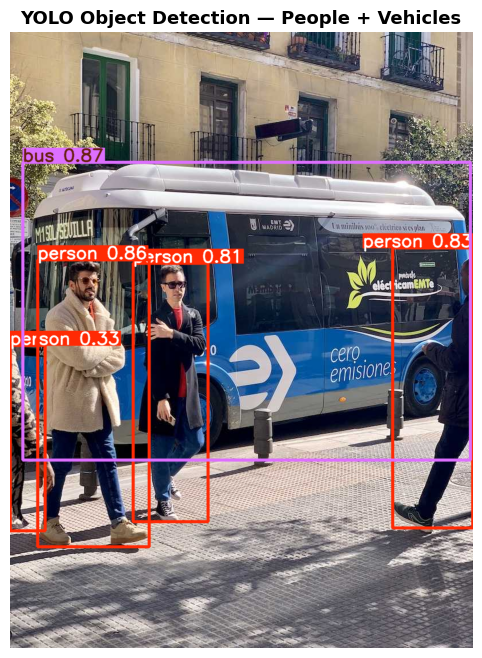


=== Detected Objects ===
  bus             → 86.8%
  person          → 86.4%
  person          → 83.3%
  person          → 81.1%
  person          → 33.4%


In [8]:
# ── PHASE 4: INFERENCE  ─────────
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

image_path = input("Enter full path to your image: ")

# Load and detect
img = Image.open(image_path).convert('RGB')
img_array = np.array(img)

results = model_yolo(img_array)

# Draw boxes automatically
annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated)
plt.title("YOLO Object Detection — People + Vehicles", fontsize=13, fontweight='bold')
plt.axis('off')
plt.show()

print("\n=== Detected Objects ===")
for box in results[0].boxes:
    class_id   = int(box.cls)
    label      = model_yolo.names[class_id]
    confidence = round(float(box.conf) * 100, 1)
    print(f"  {label:<15} → {confidence}%")

---
# ✅ Full Summary — All 3 Examples

| | Example 1 MNIST | Example 2 Cats vs Dogs | Example 3 YOLO |
|---|---|---|---|
| Task | Classification | Classification | Detection |
| Output | Label only | Label only | Label + Box |
| Dataset | MNIST 70K built-in | Cats vs Dogs 25K | COCO 80 classes |
| Image size | 28×28 grayscale | 224×224 color | Any size |
| Approach | CNN from scratch | Pretrained + Fine Tune | Pretrained direct |
| Model | Custom Sequential | VGG16 + new head | YOLOv8n |
| Classes | 10 (digits 0-9) | 2 (Cat/Dog) | 80 (people, cars...) |
| Loss | sparse categorical | binary crossentropy | built-in |
| GPU needed? | Yes (training heavy) | Yes (training heavy) | No (inference only) |
| Run where | Colab ✅ | Colab ✅ | Local or Colab ✅ |

---

## 🔑 Key Takeaways

```
1. Large dataset   → CNN from scratch    (MNIST)
2. Small dataset   → Transfer Learning  (Cats vs Dogs)
3. Task in model   → Use directly       (YOLO)
4. Task NOT in model → Fine Tune        (Cats vs Dogs with VGG16)

Classification → WHAT is in the image? → one label output
Detection      → WHAT + WHERE?         → label + bounding box

28×28 = MNIST image size (tiny, grayscale)
224×224 = VGG16 expected size (color, larger)

Inference never generates images — it always outputs labels